<a href="https://colab.research.google.com/github/oussamalembarki/concepts-ml-et-tp/blob/main/dbscan-segmentation/dbscan_customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

         frequence  montant
cluster                    
-1             4.6    240.0
 0             7.9    149.8
 1             2.1     40.6
cluster
 0    80
 1    80
-1     4
Name: count, dtype: int64


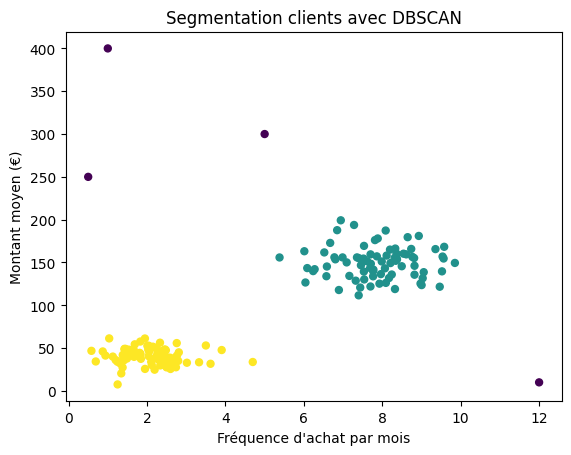

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# 1. Données fictives
fideles = pd.DataFrame({
    "frequence": np.random.normal(8, 1, 80),
    "montant":   np.random.normal(150, 20, 80)})
occasionnels = pd.DataFrame({
    "frequence": np.random.normal(2, 0.7, 80),
    "montant":   np.random.normal(40, 10, 80)})
atypiques = pd.DataFrame({
    "frequence": [1, 12, 5, 0.5],
    "montant":   [400, 10, 300, 250]})   # profils bizarres

df = pd.concat([fideles, occasionnels, atypiques], ignore_index=True)
df["frequence"] = df["frequence"].clip(lower=0)

# 2. Normalisation + DBSCAN
X = StandardScaler().fit_transform(df[["frequence", "montant"]])
df["cluster"] = DBSCAN(eps=0.5, min_samples=5).fit_predict(X)

# 3. Interprétation : moyenne par cluster
print(df.groupby("cluster")[["frequence", "montant"]].mean().round(1))
print(df["cluster"].value_counts())

# 4. Graphique
plt.scatter(df["frequence"], df["montant"], c=df["cluster"], cmap="viridis", s=25)
plt.xlabel("Fréquence d'achat par mois")
plt.ylabel("Montant moyen (€)")
plt.title("Segmentation clients avec DBSCAN")
plt.show()